# ЛР2. Разведочный и предиктивный анализ данных
**Датасет:** Superstore Sales (`train.csv`), 9800 заказанных позиций, целевой признак — `Sales`.

**Этапы:** 1) импорт и осмотр → 2) пропуски и выбросы → 3) новые признаки и кодирование → 4) стандартизация и нормализация.

*Запуск: меню Kernel → Restart & Run All (или Run → Run All Cells).*

## 0. Подготовка: библиотеки и настройки

In [15]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

%matplotlib inline

HERE = Path.cwd()                                     # папка, из которой запущен ноутбук (lab2)
DATA = HERE.parent / "Superstore Sales" / "train.csv"
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 92)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 21)


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=120)
    plt.show()                                        # в ноутбуке график показывается прямо под ячейкой
    print(f"   [график] figures/{name}")


def header(text):
    print("\n" + "=" * 70 + f"\n{text}\n" + "=" * 70)

## 1. Импорт и первичный осмотр

Загружаем `train.csv` в таблицу pandas (`DataFrame`) и смотрим: размер, типы столбцов, статистику, число уникальных значений. Цель этого шага — понять, с чем работаем.

In [16]:
header("1. ИМПОРТ ДАННЫХ")
df = pd.read_csv(DATA)
print("Файл:", DATA)
print("Размер таблицы (строк, столбцов):", df.shape)
print("\nТипы столбцов:\n", df.dtypes)
print("\nПервые 3 строки (таблица повёрнута для удобства чтения):\n", df.head(3).T)
print("\nСтатистика числовых столбцов:\n", df.describe().round(2))
print("\nЧисло уникальных значений:\n", df.nunique())



1. ИМПОРТ ДАННЫХ
Файл: d:\Study\Term 7\MMO\Superstore Sales\train.csv
Размер таблицы (строк, столбцов): (9800, 18)

Типы столбцов:
 Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

Первые 3 строки (таблица повёрнута для удобства чтения):
                                   0                     1                     2
Row ID                            1                     2                     3
Order ID             CA-2017-152156        CA-2017-152156        CA-2017-138688
Order Date               08/11/2017            08/11/2017            12/06/2017
Ship Date               

## 2. Пропуски и аномальные значения
### 2.1 Пропуски

Считаем пропуски (`isna().sum()`), рисуем карту пропусков и столбчатую диаграмму. Пропуск найден в одном столбце — `Postal Code` (11 строк, все — город Burlington, Vermont). Заполняем индексом этого города.


2. ПРОПУСКИ И АНОМАЛИИ
Пропуски по столбцам:
 Postal Code    11
dtype: int64
Полных дубликатов строк: 0


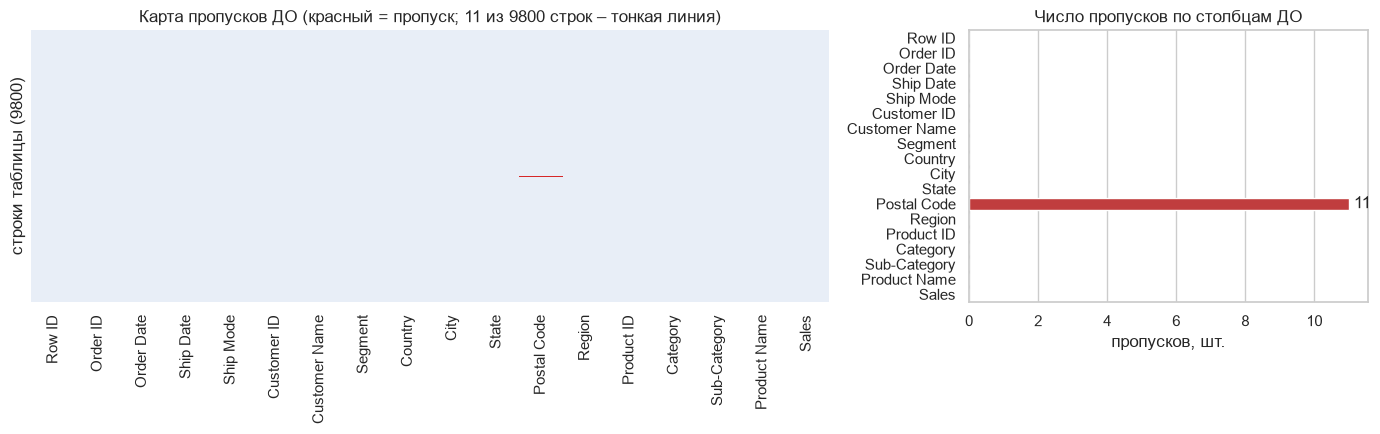

   [график] figures/01_missing_before.png

Строки с пропуском Postal Code: [['Burlington', 'Vermont']]
Пропусков Postal Code после заполнения: 0


In [17]:

header("2. ПРОПУСКИ И АНОМАЛИИ")
# 2.1 Пропуски
missing = df.isna().sum()
print("Пропуски по столбцам:\n", missing[missing > 0])
print("Полных дубликатов строк:", df.duplicated().sum())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#e8eef7", "#d62728"], ax=ax[0])
ax[0].set_title("Карта пропусков ДО (красный = пропуск; 11 из 9800 строк – тонкая линия)")
ax[0].set_ylabel("строки таблицы (9800)")
sns.barplot(x=missing.values, y=missing.index, color="tab:red", ax=ax[1])
ax[1].set_title("Число пропусков по столбцам ДО")
ax[1].set_xlabel("пропусков, шт.");  ax[1].set_ylabel("")
for i, v in enumerate(missing.values):
    if v > 0:
        ax[1].text(v, i, f" {v}", va="center")
save("01_missing_before.png")

rows = df[df["Postal Code"].isna()]
print("\nСтроки с пропуском Postal Code:", rows[["City", "State"]].drop_duplicates().values.tolist())
# Ищем индекс этого города в самих данных; если других записей нет, ставим известный индекс г. Берлингтон (Вермонт).
known = df.dropna(subset=["Postal Code"]).groupby(["City", "State"])["Postal Code"].agg(lambda s: s.mode().iloc[0])
for idx, r in rows.iterrows():
    df.loc[idx, "Postal Code"] = known.get((r["City"], r["State"]), 5401)
df["Postal Code"] = df["Postal Code"].astype(int)
print("Пропусков Postal Code после заполнения:", df["Postal Code"].isna().sum())

### 2.2 Даты и логические проверки

Преобразуем текстовые даты в тип `datetime` (формат день/месяц/год) и проверяем здравый смысл: дата отгрузки не раньше даты заказа, продажи положительные.

In [18]:
# 2.2 Приводим даты к типу datetime (формат в файле день/месяц/год)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d/%m/%Y")

# 2.3 Логические аномалии
print("\nЛогические проверки:")
print("  дата отгрузки раньше даты заказа:", (df["Ship Date"] < df["Order Date"]).sum())
print("  Sales <= 0:", (df["Sales"] <= 0).sum())


Логические проверки:
  дата отгрузки раньше даты заказа: 0
  Sales <= 0: 0


### 2.3 Выбросы в `Sales`: статистика и графики

Правило IQR и z-score показывают много «выбросов» из-за сильной скошенности. Применяем IQR к `log(1+Sales)` — остаётся 10 настоящих выбросов.


Sales: Q1=17.25, Q3=210.61, IQR=193.36
  границы по правилу IQR: [-272.79; 500.64], выбросов: 1145
  выбросов по правилу |z| > 3: 123
  коэффициент асимметрии (skew): 12.98  (для симметричного распределения около 0)

По log(1+Sales): границы [-0.77; 9.03] -> в Sales [-0.54; 8354.87]
  выбросов: 10


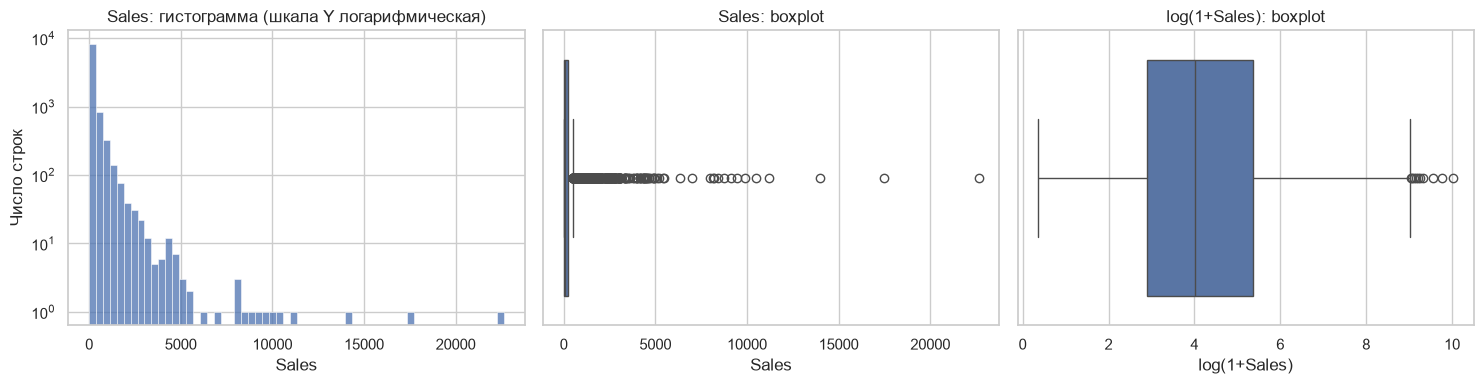

   [график] figures/02_outliers_before.png

Сколько значений выше верхней границы IQR по категориям:
 Category
Furniture          459
Office Supplies    292
Technology         394
Name: Sales, dtype: int64


In [19]:
# 2.4 Выбросы в Sales: статистические методы
s = df["Sales"]
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
z = (s - s.mean()) / s.std()
print(f"\nSales: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"  границы по правилу IQR: [{low:.2f}; {high:.2f}], выбросов: {((s < low) | (s > high)).sum()}")
print(f"  выбросов по правилу |z| > 3: {(z.abs() > 3).sum()}")
print(f"  коэффициент асимметрии (skew): {s.skew():.2f}  (для симметричного распределения около 0)")

# Распределение сильно скошено вправо, поэтому правило IQR применяем к логарифму продаж.
df["log_sales"] = np.log1p(df["Sales"])
lq1, lq3 = df["log_sales"].quantile([0.25, 0.75])
liqr = lq3 - lq1
llow, lhigh = lq1 - 1.5 * liqr, lq3 + 1.5 * liqr
n_out = ((df["log_sales"] < llow) | (df["log_sales"] > lhigh)).sum()
print(f"\nПо log(1+Sales): границы [{llow:.2f}; {lhigh:.2f}] -> в Sales [{np.expm1(llow):.2f}; {np.expm1(lhigh):.2f}]")
print("  выбросов:", n_out)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["Sales"], bins=60, ax=ax[0]);            ax[0].set_title("Sales: гистограмма (шкала Y логарифмическая)")
ax[0].set_yscale("log");  ax[0].set_ylabel("Число строк")
sns.boxplot(x=df["Sales"], ax=ax[1]);                    ax[1].set_title("Sales: boxplot")
sns.boxplot(x=df["log_sales"], ax=ax[2]);                ax[2].set_title("log(1+Sales): boxplot"); ax[2].set_xlabel("log(1+Sales)")
save("02_outliers_before.png")

top = df.groupby("Category")["Sales"].apply(lambda x: x[x > high].count())
print("\nСколько значений выше верхней границы IQR по категориям:\n", top)

### 2.4 Устранение выбросов (винзоризация)

Значения за границей заменяем самой границей (`clip`), строки не удаляем — крупные продажи реальны.

In [20]:
# Устранение: винзоризация (значения за границами заменяем на границу), строки не удаляем.
sales_low, sales_high = np.expm1(llow), np.expm1(lhigh)
df["Sales_raw"] = df["Sales"]
df["Sales"] = df["Sales"].clip(lower=max(sales_low, 0), upper=sales_high)
df["log_sales"] = np.log1p(df["Sales"])
print(f"\nВыбросы обрезаны по границам [{max(sales_low, 0):.2f}; {sales_high:.2f}]. Изменено значений:",
      (df["Sales"] != df["Sales_raw"]).sum())


Выбросы обрезаны по границам [0.00; 8354.87]. Изменено значений: 10


### 2.5 Проверка графиками: выбросов и пропусков больше нет

Сравниваем «до» и «после».

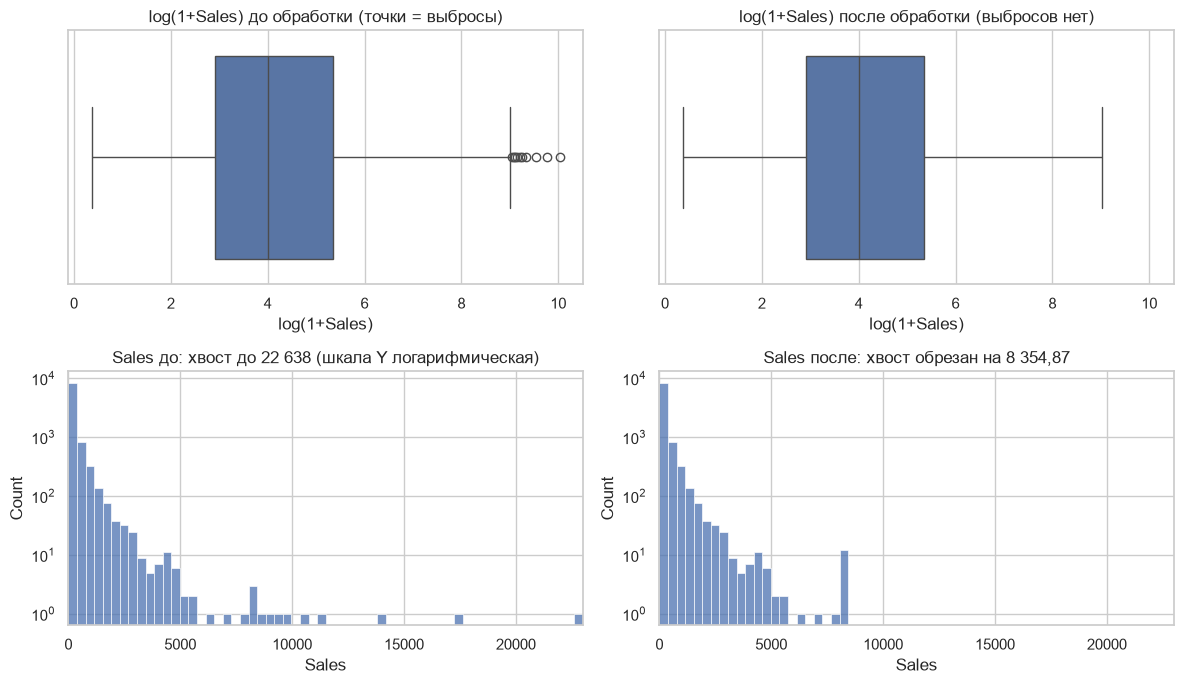

   [график] figures/03_outliers_after.png
Выбросов по log(1+Sales) после обработки: 0


In [21]:
# Повторная проверка графиками. Из-за сильной скошенности сравниваем на логарифмической шкале:
# именно на ней выбросы определялись, и после обработки точек за усами быть не должно.
df["log_sales_raw"] = np.log1p(df["Sales_raw"])
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
sns.boxplot(x=df["log_sales_raw"], ax=ax[0, 0]); ax[0, 0].set_title("log(1+Sales) до обработки (точки = выбросы)"); ax[0, 0].set_xlabel("log(1+Sales)")
sns.boxplot(x=df["log_sales"], ax=ax[0, 1]);     ax[0, 1].set_title("log(1+Sales) после обработки (выбросов нет)"); ax[0, 1].set_xlabel("log(1+Sales)"); ax[0, 1].set_xlim(ax[0, 0].get_xlim())
sns.histplot(df["Sales_raw"], bins=60, binrange=(0, 23000), ax=ax[1, 0]); ax[1, 0].set_title("Sales до: хвост до 22 638 (шкала Y логарифмическая)"); ax[1, 0].set_xlabel("Sales"); ax[1, 0].set_yscale("log"); ax[1, 0].set_xlim(0, 23000)
sns.histplot(df["Sales"], bins=60, binrange=(0, 23000), ax=ax[1, 1]);     ax[1, 1].set_title("Sales после: хвост обрезан на 8 354,87"); ax[1, 1].set_yscale("log"); ax[1, 1].set_xlim(0, 23000)
save("03_outliers_after.png")
lq1b, lq3b = df["log_sales"].quantile([0.25, 0.75])
liqrb = lq3b - lq1b
left = ((df["log_sales"] < lq1b - 1.5 * liqrb) | (df["log_sales"] > lq3b + 1.5 * liqrb)).sum()
print("Выбросов по log(1+Sales) после обработки:", left)
df = df.drop(columns=["log_sales_raw"])

Карта пропусков после обработки

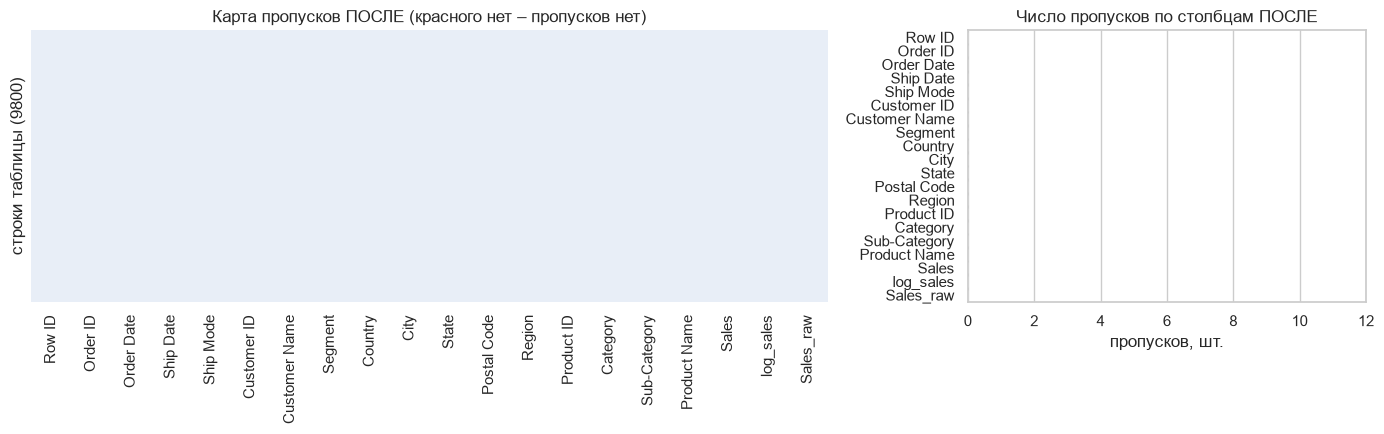

   [график] figures/04_missing_after.png
Пропусков во всей таблице: 0
Skew Sales после обработки: 7.46 (хвост остаётся: крупные покупки это реальные данные, а не ошибки)


In [22]:
missing_after = df.isna().sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#e8eef7", "#d62728"], ax=ax[0])
ax[0].set_title("Карта пропусков ПОСЛЕ (красного нет – пропусков нет)")
ax[0].set_ylabel("строки таблицы (9800)")
sns.barplot(x=missing_after.values, y=missing_after.index, color="tab:green", ax=ax[1])
ax[1].set_xlim(0, 12)                       # та же шкала, что до обработки
ax[1].set_title("Число пропусков по столбцам ПОСЛЕ")
ax[1].set_xlabel("пропусков, шт.");  ax[1].set_ylabel("")
save("04_missing_after.png")
print("Пропусков во всей таблице:", int(df.isna().sum().sum()))
print("Skew Sales после обработки:", round(df["Sales"].skew(), 2), "(хвост остаётся: крупные покупки это реальные данные, а не ошибки)")

## 3. Новые признаки и кодирование

Создаём признаки из дат и групповых счётчиков, бинаризуем, кодируем категории (One-Hot и частотное кодирование).

In [23]:
header("3. НОВЫЕ ПРИЗНАКИ И КОДИРОВАНИЕ")

# 3.1 Генерация признаков
df["order_year"] = df["Order Date"].dt.year
df["order_month"] = df["Order Date"].dt.month
df["order_dayofweek"] = df["Order Date"].dt.dayofweek          # 0 = понедельник
df["is_weekend_order"] = (df["order_dayofweek"] >= 5).astype(int)
df["ship_delay_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["order_size"] = df.groupby("Order ID")["Row ID"].transform("count")   # позиций в заказе
df["customer_orders"] = df.groupby("Customer ID")["Order ID"].transform("nunique")  # заказов у клиента
print("Новые признаки: order_year, order_month, order_dayofweek, is_weekend_order, ship_delay_days,")
print("                order_size (позиций в заказе), customer_orders (заказов у клиента)")
print(df[["order_year", "order_month", "order_dayofweek", "ship_delay_days", "order_size", "customer_orders"]].describe().T.round(2))


3. НОВЫЕ ПРИЗНАКИ И КОДИРОВАНИЕ
Новые признаки: order_year, order_month, order_dayofweek, is_weekend_order, ship_delay_days,
                order_size (позиций в заказе), customer_orders (заказов у клиента)
                  count     mean   std     min     25%     50%     75%     max
order_year       9800.0  2016.72  1.12  2015.0  2016.0  2017.0  2018.0  2018.0
order_month      9800.0     7.82  3.28     1.0     5.0     9.0    11.0    12.0
order_dayofweek  9800.0     2.99  2.18     0.0     1.0     3.0     5.0     6.0
ship_delay_days  9800.0     3.96  1.75     0.0     3.0     4.0     5.0     7.0
order_size       9800.0     2.98  1.96     1.0     1.0     3.0     4.0    14.0
customer_orders  9800.0     7.24  2.54     1.0     5.0     7.0     9.0    17.0


C:\Users\arsen\AppData\Local\Temp\ipykernel_29528\189153009.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["order_dayofweek"] = df["Order Date"].dt.dayofweek          # 0 = понедельник


### 3.2 Бинаризация и частотное кодирование

In [24]:
# 3.2 Бинаризация
df["is_high_sale"] = (df["Sales"] > df["Sales"].median()).astype(int)     # продажа выше медианы
df["is_fast_ship"] = (df["ship_delay_days"] <= 2).astype(int)              # отгрузка за 2 дня и быстрее
print("\nБинаризация: is_high_sale (Sales > медианы), is_fast_ship (доставка <= 2 дней)")

# 3.3 Частотное кодирование для признака с большим числом значений (State: ~49)
df["state_freq"] = df["State"].map(df["State"].value_counts(normalize=True))
print("Частотное кодирование: state_freq (доля заказов штата)")


Бинаризация: is_high_sale (Sales > медианы), is_fast_ship (доставка <= 2 дней)
Частотное кодирование: state_freq (доля заказов штата)


### 3.3 One-Hot Encoding и очистка столбцов

In [25]:
# 3.4 One-Hot Encoding
ohe_cols = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]
df_ohe = pd.get_dummies(df, columns=ohe_cols, prefix=[c.replace(" ", "_").replace("-", "_") for c in ohe_cols],
                        dtype=int)
new_cols = [c for c in df_ohe.columns if c not in df.columns]
print(f"\nOHE для {ohe_cols}: добавлено {len(new_cols)} столбцов")
print("Примеры:", new_cols[:8])

# Убираем идентификаторы, названия и столбцы без информации (Country = одна страна)
drop_cols = ["Row ID", "Order ID", "Customer ID", "Customer Name", "Product ID", "Product Name",
             "City", "State", "Country", "Order Date", "Ship Date", "Sales_raw"]
data = df_ohe.drop(columns=drop_cols)
print("\nУдалены (идентификаторы, текст, константа):", drop_cols)
print("Итоговая форма:", data.shape)


OHE для ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']: добавлено 31 столбцов
Примеры: ['Ship_Mode_First Class', 'Ship_Mode_Same Day', 'Ship_Mode_Second Class', 'Ship_Mode_Standard Class', 'Segment_Consumer', 'Segment_Corporate', 'Segment_Home Office', 'Region_Central']

Удалены (идентификаторы, текст, константа): ['Row ID', 'Order ID', 'Customer ID', 'Customer Name', 'Product ID', 'Product Name', 'City', 'State', 'Country', 'Order Date', 'Ship Date', 'Sales_raw']
Итоговая форма: (9800, 44)


### 3.4 Корреляции и графики новых признаков

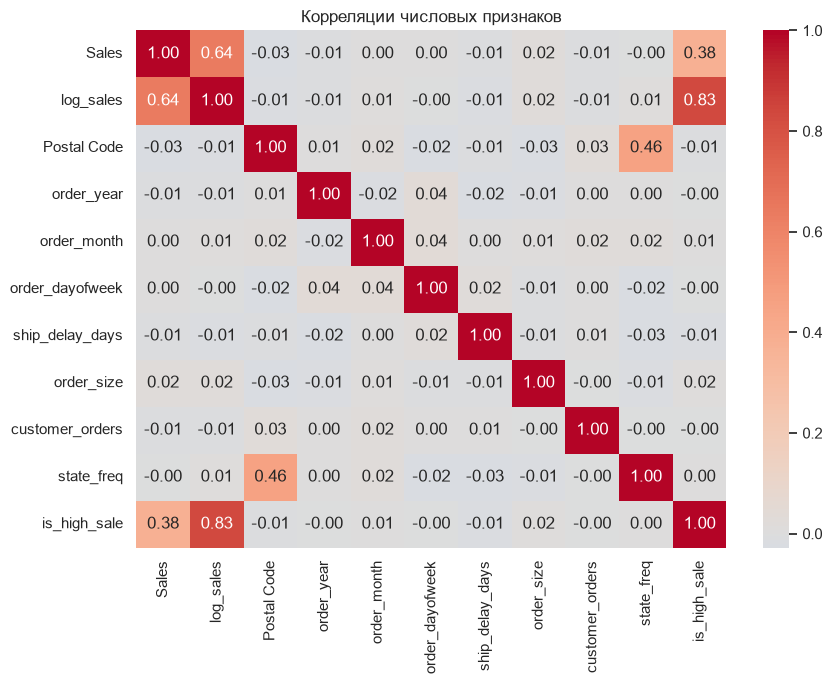

   [график] figures/05_correlation.png


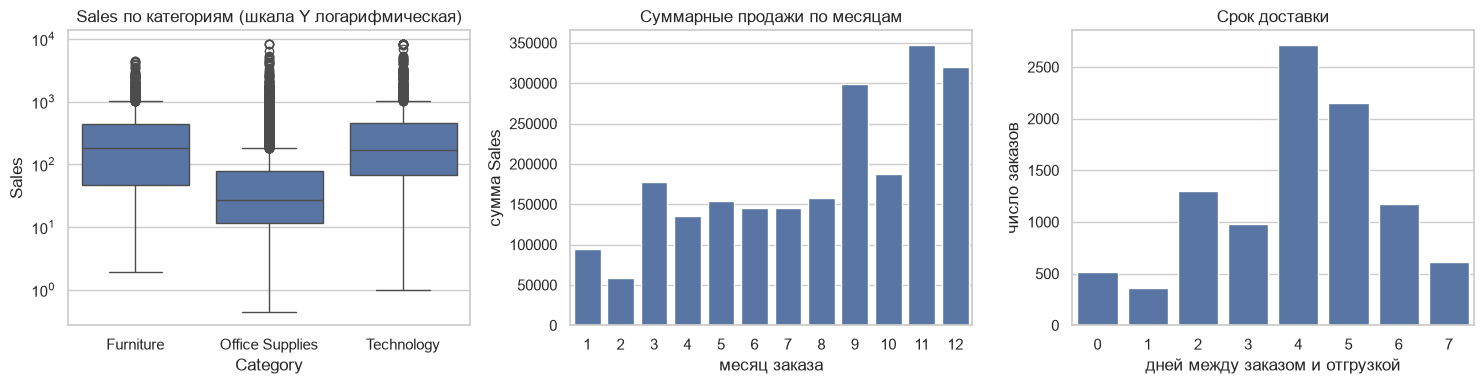

   [график] figures/06_new_features.png


In [26]:
# Тепловая карта корреляций числовых признаков
num_for_corr = ["Sales", "log_sales", "Postal Code", "order_year", "order_month", "order_dayofweek",
                "ship_delay_days", "order_size", "customer_orders", "state_freq", "is_high_sale"]
plt.figure(figsize=(9, 7))
sns.heatmap(data[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков")
save("05_correlation.png")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Category", y="Sales", ax=ax[0]);       ax[0].set_title("Sales по категориям (шкала Y логарифмическая)"); ax[0].set_yscale("log")
sns.barplot(data=df, x="order_month", y="Sales", estimator="sum", errorbar=None, ax=ax[1])
ax[1].set_title("Суммарные продажи по месяцам"); ax[1].set_xlabel("месяц заказа"); ax[1].set_ylabel("сумма Sales")
sns.countplot(data=df, x="ship_delay_days", ax=ax[2]);         ax[2].set_title("Срок доставки"); ax[2].set_xlabel("дней между заказом и отгрузкой"); ax[2].set_ylabel("число заказов")
save("06_new_features.png")

## 4. Стандартизация и нормализация

`StandardScaler` (среднее 0, std 1) и `MinMaxScaler` (диапазон [0; 1]).


4. СТАНДАРТИЗАЦИЯ И НОРМАЛИЗАЦИЯ
До масштабирования:
                      mean       std      min       max
Sales              226.90    543.62     0.44   8354.87
log_sales            4.16      1.59     0.37      9.03
ship_delay_days      3.96      1.75     0.00      7.00
order_size           2.98      1.96     1.00     14.00
customer_orders      7.24      2.54     1.00     17.00
Postal Code      55217.34  32066.75  1040.00  99301.00
order_year        2016.72      1.12  2015.00   2018.00
order_month          7.82      3.28     1.00     12.00
order_dayofweek      2.99      2.18     0.00      6.00
state_freq           0.08      0.07     0.00      0.20

После:
                  mean   std   min    max
Sales           -0.00  1.00 -0.42  14.95
log_sales       -0.00  1.00 -2.38   3.06
ship_delay_days  0.00  1.00 -2.26   1.74
order_size       0.00  1.00 -1.01   5.62
customer_orders  0.00  1.00 -2.46   3.85
Postal Code      0.55  0.33  0.00   1.00
order_year       0.57  0.37  0.00   1.00
ord

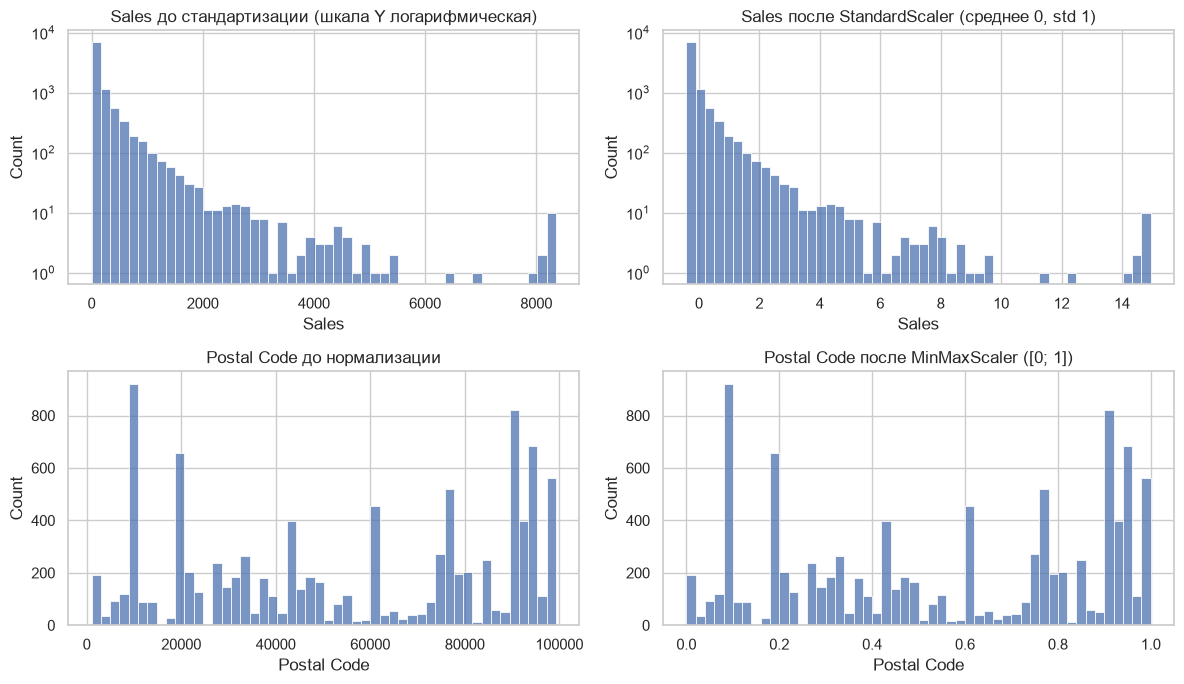

   [график] figures/07_scaling.png


In [27]:
header("4. СТАНДАРТИЗАЦИЯ И НОРМАЛИЗАЦИЯ")
std_cols = ["Sales", "log_sales", "ship_delay_days", "order_size", "customer_orders"]      # -> среднее 0, std 1
mm_cols = ["Postal Code", "order_year", "order_month", "order_dayofweek", "state_freq"]  # -> диапазон [0; 1]

scaled = data.copy()
scaled[std_cols] = StandardScaler().fit_transform(data[std_cols])
scaled[mm_cols] = MinMaxScaler().fit_transform(data[mm_cols])

print("До масштабирования:\n", data[std_cols + mm_cols].describe().loc[["mean", "std", "min", "max"]].round(2).T)
print("\nПосле:\n", scaled[std_cols + mm_cols].describe().loc[["mean", "std", "min", "max"]].round(2).T)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
sns.histplot(data["Sales"], bins=50, ax=ax[0, 0]);     ax[0, 0].set_title("Sales до стандартизации (шкала Y логарифмическая)"); ax[0, 0].set_yscale("log")
sns.histplot(scaled["Sales"], bins=50, ax=ax[0, 1]);   ax[0, 1].set_title("Sales после StandardScaler (среднее 0, std 1)"); ax[0, 1].set_yscale("log")
sns.histplot(data["Postal Code"], bins=50, ax=ax[1, 0]);   ax[1, 0].set_title("Postal Code до нормализации")
sns.histplot(scaled["Postal Code"], bins=50, ax=ax[1, 1]); ax[1, 1].set_title("Postal Code после MinMaxScaler ([0; 1])")
save("07_scaling.png")

### Сохранение результата

In [28]:
out = HERE / "superstore_prepared.csv"
scaled.to_csv(out, index=False)
print(f"\nГотовая таблица ({scaled.shape[0]} строк, {scaled.shape[1]} столбцов) сохранена: {out.name}")
print("Пропусков в итоговой таблице:", int(scaled.isna().sum().sum()))


Готовая таблица (9800 строк, 44 столбцов) сохранена: superstore_prepared.csv
Пропусков в итоговой таблице: 0


## Итог
- Таблица: **9800 × 18 → 9800 × 44**, пропусков нет.
- Выбросы `Sales` обработаны винзоризацией (10 значений).
- Новые признаки: 7 из дат и счётчиков, 2 бинарных (`is_high_sale`, `is_fast_ship`), `state_freq`, `log_sales` + 31 столбец One-Hot.
- Числовые признаки приведены к одному масштабу.